In [1]:
import pandas as pd
from sklearn.linear_model import LogisticRegressionCV, LogisticRegression
from sklearn import metrics
import numpy as np
import altair as alt
import seaborn as sns
import matplotlib.pyplot as plt
alt.renderers.enable('notebook')
alt.data_transformers.disable_max_rows()
pd.set_option("display.max_rows", 999)

In [35]:
dataset, peplen, netmhc_v = 'MouseEL4', '9', 'NetMHC-4.0'
f = 'finalTables/{}_{}_{}.tsv.gz'.format(dataset, peplen, netmhc_v)
full_df = pd.read_csv(f, sep = '\t', index_col=0)
full_df.shape

(611225, 37)

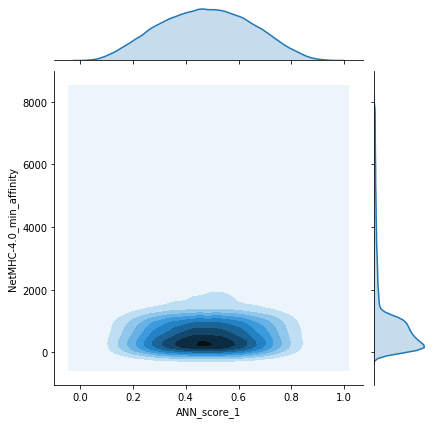

In [39]:
sns.jointplot(full_df.ANN_score_1, np.log(full_df['NetMHC-4.0_min_affinity']), kind='kde')

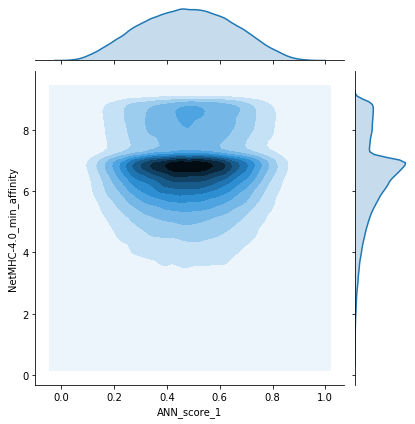

In [41]:
sns.jointplot(full_df.ANN_score_1, np.log(full_df['NetMHC-4.0_min_affinity']), kind='kde')

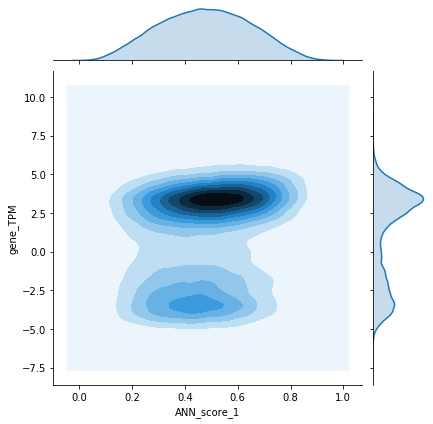

In [42]:
sns.jointplot(full_df.ANN_score_1, np.log(full_df['gene_TPM']), kind='kde')

In [20]:
%%time

df = full_df.copy()

def join_genes(d):
    for col in d.columns[d.columns.str.match('ANN_s')]:
        d[col] = d[col].max()
    d.gene_TPM = d.gene_TPM.sum()  # if peptide twice in gene double value (should be very rare)
    return d.iloc[[0]]

df = df[~((df.peptide_detected == False) & (df.transcript_is_source == True))]
df = df[df['NetMHC-4.0_min_affinity'] < 250]
df = df.drop(['gene', 'gene_is_source', 'transcript', 'transcript_is_source', 'transcript_TPM'], axis=1)
df = df.groupby("peptide", sort=False).apply(join_genes).droplevel(0)

CPU times: user 4min 34s, sys: 358 ms, total: 4min 35s
Wall time: 4min 34s


In [21]:
%%time

df = full_df.copy()

def join_genes(d):
    for col in d.columns[d.columns.str.match('ANN_s')]:
        d[col] = d[col].max()
    d.gene_TPM = d.gene_TPM.sum()  # if peptide twice in gene double value (should be very rare)
    return d.iloc[[0]]

df = df[~((df.peptide_detected == False) & (df.transcript_is_source == True))]
df = df[df['NetMHC-4.0_min_affinity'] < 250]
df = df.drop(['gene', 'gene_is_source', 'transcript', 'transcript_is_source', 'transcript_TPM'], axis=1)
df = df.groupby("peptide").apply(join_genes).droplevel(0)

CPU times: user 4min 32s, sys: 203 ms, total: 4min 32s
Wall time: 4min 32s


In [23]:
df['ANN_score'] = df.ANN_score_1
df['ANN_shuffle_score'] = df.ANN_shuffle_score_2

## AUC

In [5]:
fpr, tpr, thresholds = metrics.roc_curve(df.peptide_detected, df.ANN_score)
auc = metrics.auc(fpr, tpr)
print(auc)

0.6490699165166478


In [6]:
fpr, tpr, thresholds = metrics.roc_curve(df.peptide_detected, df.ANN_shuffle_score)
auc = metrics.auc(fpr, tpr)
print(auc)

0.6271080112371915


## PPV

In [32]:
subset = df[['peptide_detected', 'ANN_score', 'gene_TPM', 'NetMHC-4.0_min_affinity']]
subset.peptide_detected.sum() / subset.peptide_detected.shape[0]

0.01912117281767087

In [33]:
subset.sort_values('ANN_score', ascending=False).iloc[:1000].peptide_detected.sum()/1000

0.065

In [34]:
subset.sort_values('ANN_score', ascending=False).iloc[:1000]

,peptide_detected,ANN_score,gene_TPM,NetMHC-4.0_min_affinity
peptide,,,,
ASLNRRIQL,False,0.9406,832.3969,153.61
AVLLKHQEL,False,0.9404,12.4947,241.16
KAMENIGEL,True,0.9395,77.8336,22.74
MNFLLKAEV,False,0.9312,1010.2357,172.92
MALANLLQI,False,0.9289,197.8750,13.20
...,...,...,...,...
VNPQMFQDL,False,0.7959,42.4998,44.81
IVYLVHCGI,False,0.7958,257.5852,118.03
ISHAQYSAL,False,0.7958,36.0414,14.52


# control

In [ ]:
s = pd.read_csv('parsed/peptides.source.all.txt', names=['peptide'])
s['presence'] = True
ns = pd.read_csv('parsed/peptides.nonsource.all.txt', names=['peptide'])
ns['presence'] = False
joined = pd.concat([s, ns])
joined.shape

In [ ]:
joined.presence.sum() / joined.shape[0]

In [ ]:
dataset, peplen, netmhc_v = 'HumanBLCL', '9', 'NetMHC-4.0'
f = 'finalTables/{}_{}_{}.tsv.gz'.format(dataset, peplen, netmhc_v)
full_df = pd.read_csv(f, sep = '\t', index_col=0)
full_df.shape

In [ ]:
full_df = full_df.merge(joined, on='peptide', how='right')
full_df.drop(full_df[np.isnan(full_df.ANN_score_1)].index, inplace=True)  # Chose ANN_score because dtype = float
full_df.peptide_detected = full_df.peptide_detected.astype(bool)
full_df.shape

In [ ]:
full_df

In [ ]:
df = full_df[~((full_df.peptide_detected == False) & (full_df.transcript_is_source == True))]
df = df.drop(['transcript_is_source', 'transcript_TPM'], axis=1)
df.shape

In [ ]:
df.peptide_detected.sum() / df.shape[0]

In [ ]:
# def join_transcripts(df):
#     df.ANN_score = df.ANN_score.max()
#     df.ANN_shuffle_score = df.ANN_shuffle_score.max()
#     return df.iloc[[0]]

# df = df.groupby(["peptide", "gene"]).apply(join_transcripts).droplevel([0, 1])
# df.shape

In [ ]:
%%time

def join_genes(df):
    df.ANN_score = df.ANN_score.max()
    df.ANN_shuffle_score = df.ANN_shuffle_score.max()
    df.gene_TPM = df.gene_TPM.sum()
    return df.iloc[[0]]

df = df.groupby("peptide").apply(join_genes).droplevel(0)
df.shape

In [ ]:
df.peptide_detected.sum() / df.shape[0]

In [ ]:
df[(df.peptide_detected != df.presence)][['peptide', 'peptide_detected', 'gene_TPM', 'NetMHC-4.0_min_rank']]

In [ ]:
pos_acc = sum((df.peptide_detected == True) & (df.ANN_score >= 0.5)) / sum(df.peptide_detected == True)
neg_acc = sum((df.peptide_detected == False) & (df.ANN_score < 0.5)) / sum(df.peptide_detected == False)
print(pos_acc, neg_acc)

In [ ]:
pos_acc = sum((df.presence == True) & (df.ANN_score >= 0.5)) / sum(df.presence == True)
neg_acc = sum((df.presence == False) & (df.ANN_score < 0.5)) / sum(df.presence == False)
print(pos_acc, neg_acc)

In [ ]:
dfbak = df

In [ ]:
df = full_df.copy()
#df = df[df['NetMHC-4.0_min_affinity'] < 1250]
df = df[~((df.peptide_detected == False) & (df.transcript_is_source == True))]
weights = abs(df.peptide_detected - (df.peptide_detected.sum() / df.peptide_detected.shape[0]))
#weights = [1]*df.peptide_detected.shape[0]
#df = df.sample(n=100000, weights=weights)#, random_state=0)
df = df.rename({"NetMHC-4.0_min_affinity":"minBS", "NetMHCpan-4.0a_min_affinity":"minBS"}, axis=1)
df = df[["peptide_detected", "ANN_score", "gene_TPM", "minBS"]]
df = df.rename({"peptide_detected":"Class",
                "gene_TPM": "mean_log_tpm"}, axis=1)
df.mean_log_tpm = np.log(df.mean_log_tpm)
df.minBS = np.log(df.minBS)
df = df.dropna(how='any')
print(df.Class.sum(), df.Class.shape[0], df.Class.sum()/df.Class.shape[0])

In [ ]:
x_labels = ['minBS']
x_labels = ['mean_log_tpm']
#x_labels = ['ANN_score']
x_labels = ['minBS', 'mean_log_tpm']
#x_labels = ["ANN_score", "minBS"]
#x_labels = ["ANN_score", "mean_log_tpm"]
#x_labels = ["ANN_score", "mean_log_tpm", "minBS"]
prefix = "-".join(x_labels)
print(prefix)
print("10X cross validation...")

weights = abs(df.Class - (df.Class.sum() / df.Class.shape[0]))

X, y = df[x_labels], df.Class
clf = LogisticRegression(multi_class='auto', solver='lbfgs', random_state=0, 
                           class_weight="balanced", max_iter=100)
                           #class_weight={False:df.Class.sum(), True:df.Class.shape[0]-df.Class.sum()}, max_iter=0)
clf.fit(X, y)

print("predictions...")
scores = clf.predict_proba(X)[:,1]
predictions = clf.predict(X)
accuracy = clf.score(X,y,weights)
print("prediction accuracy:", accuracy)
print("Regression coef %s:" % x_labels, clf.coef_)
print("Regression intercept %s:" % x_labels, clf.intercept_)

print("roc curve...")
fpr, tpr, thresholds = metrics.roc_curve(df.Class.to_numpy(), scores)
dct =  {'FPR': fpr, 'TPR': tpr, 'THRESHOLDS': thresholds}
auc = metrics.auc(fpr, tpr)
print(auc)

pos_acc = sum((df.Class == True) & (predictions)) / sum(df.Class == True)
neg_acc = sum((df.Class == False) & ~(predictions)) / sum(df.Class == False)
print(pos_acc)
print(neg_acc)

In [ ]:
from scipy.special import expit
df2 = df.copy()
df2['scores'] = scores
df2['y'] = expit(np.multiply(df2[x_labels].to_numpy(), clf.coef_).sum(axis=1) + clf.intercept_).ravel()
df2 = df2.sample(n=10000, weights=weights)#, random_state=0)
chart = alt.Chart(df2).mark_circle(size=50).encode(
    x='scores',
    y='ANN_score',
    #y='Class:Q',
    color='Class'
)

line = alt.Chart(df2).mark_line(color='black').encode(
    x='scores',
    y='y'
)

(chart + line).interactive()

In [ ]:
def apply_combination(dataset, peplen, netmhc_v, x_labels):
    f = 'finalTables/{}_{}_{}.tsv.gz'.format(dataset, peplen, netmhc_v)
    df = pd.read_csv(f, sep = '\t', index_col=0)

    # Remove non-detected peptides detected in source transcripts
    df = df[~((df.peptide_detected == False) & (df.transcript_is_source == True))]
    
    df = df.rename({"NetMHC-4.0_min_affinity":"minBS", "NetMHCpan-4.0a_min_affinity":"minBS"}, axis=1)
    
    df = df[["peptide_detected", "ANN_score", "gene_TPM", "minBS"]]
    df = df.rename({"peptide_detected":"Class",
                    "gene_TPM": "mean_log_tpm"}, axis=1)
    df.mean_log_tpm = np.log(df.mean_log_tpm)
    df = df[df.minBS < 500]
    #df.minBS = np.log(df.minBS)
    
    prefix = "-".join(x_labels)
    print(prefix)
    print("10X cross validation...")
    X, y = df[x_labels], df.Class
    clf = LogisticRegression(random_state=0, multi_class='auto',
                               class_weight="balanced", max_iter=1)
                               #class_weight={False:df.Class.sum(), True:df.Class.shape[0]-df.Class.sum()})
    clf.fit(X, y)
    
    print("predictions...")
    scores = clf.predict_proba(X)[:,1]
    predictions = clf.predict(X)
    accuracy = clf.score(X,y)
    print("prediction accuracy:", accuracy)
    print("Regression coef %s:" % x_labels, clf.coef_)
    
    print("roc curve...")
    fpr, tpr, thresholds = metrics.roc_curve(df.Class.to_numpy(), scores)
    dct =  {'FPR': fpr, 'TPR': tpr, 'THRESHOLDS': thresholds}
    auc = metrics.auc(fpr, tpr)
    print(auc)
    
    pos_acc = sum((df.Class == True) & (predictions)) / sum(df.Class == True)
    neg_acc = sum((df.Class == False) & ~(predictions)) / sum(df.Class == False)
    print(sum((df.Class == True) & (predictions)))
    print(pos_acc)
    print(neg_acc)
    print(df.Class.sum(), df.shape[0])
    print(predictions)
    
    global df_metrics
    df_metrics.loc[df_metrics.shape[0]] = [dataset, peplen, netmhc_v, prefix, 'AUC', auc]
    df_metrics.loc[df_metrics.shape[0]] = [dataset, peplen, netmhc_v, prefix, 'Accuracy', accuracy]
    df_metrics.loc[df_metrics.shape[0]] = [dataset, peplen, netmhc_v, prefix, 'posAcc', pos_acc]
    df_metrics.loc[df_metrics.shape[0]] = [dataset, peplen, netmhc_v, prefix, 'negAcc', neg_acc]

    seen = set()
    reduced = [x for x in zip(np.round(fpr, 3), np.round(tpr, 3)) if x not in seen and not seen.add(x)]
    df_r = pd.DataFrame(reduced, columns=['fpr', 'tpr'])
    df_r['Dataset'] = dataset
    df_r['peptideLength'] = peplen
    df_r['NetMHCVersion'] = netmhc_v
    df_r['Combination'] = prefix
    
    global df_roc
    df_roc = pd.concat([df_roc, df_r], sort=False)
    
    return df[df.Class == True].ANN_score, df[df.Class == False].ANN_score

In [ ]:
combinations = [
    #["ANN_score", "mean_log_tpm", "minBS"],
    #["ANN_score", "minBS"],
    #["ANN_score", "mean_log_tpm"],
    #["mean_log_tpm", "minBS"],
    ["minBS"],
    ["mean_log_tpm"],
    ["ANN_score"]
]

In [ ]:
df_metrics = pd.DataFrame(columns=['Dataset', 'peptideLength', 'NetMHCVersion', 'Combination', 'metric', 'value'])

df_roc = pd.DataFrame(columns=['Dataset', 'peptideLength', 'NetMHCVersion', 'Combination', 'fpr', 'tpr'])
df_roc.loc[0] = ['diagonal', 'mid', 'line', 'plotted', 0, 0]
df_roc.loc[1] = ['diagonal', 'mid', 'line', 'plotted', 1, 1]

df_pr = pd.DataFrame(columns=['Dataset', 'peptideLength', 'NetMHCVersion', 'Combination', 'precision', 'recall'])

datasets = ['HumanBLCL']
peplens = ['9']#, '9', '10', '11']
netmhc_vs = ['NetMHC-4.0']#, 'NetMHCpan-4.0a']

#fix, axs = plt.subplots(len(datasets)*len(netmhc_v), len(peplens), figsize=(10,10))
fix, axs = plt.subplots(len(datasets)*len(netmhc_vs)*len(combinations), len(peplens), figsize=(10,10))
print(len(datasets)*len(netmhc_vs)*len(combinations), len(peplens))
plt.tight_layout()
for a, c in enumerate(combinations):
    for i, d in enumerate(datasets):
        for j, l in enumerate(peplens):
            for k, v in enumerate(netmhc_vs):
                s, ns = apply_combination(d, l, v, c)
                sns.distplot(s, ax=axs[i+k+a][j])
                sns.distplot(ns, ax=axs[i+k+a][j])

In [ ]:
chart = alt.Chart(df_roc).transform_calculate(
    cat = "datum.Dataset + '-' + datum.peptideLength + '-' + datum.NetMHCVersion"
).mark_line().encode(
    x=alt.X('fpr', title='False positive rate'),
    y=alt.Y('tpr', title='True positive rate'),
    color='cat:N'
)

chart

In [ ]:
df_metrics3 = df_metrics
df_roc3 = df_roc

In [ ]:
df_metrics3

In [ ]:
chart = alt.Chart(df_metrics).transform_calculate(
    cat = "datum.Combination"
).mark_bar().encode(
    x=alt.X('cat:N', title='Dataset'),
    y=alt.Y('value', title='Value'),
    color='cat:N',
    column='metric:N'
)

chart.properties(width=150)

## Heavy lifting

In [ ]:
def apply_dataset(dataset, peplen, netmhc_v,):
    f = 'finalTables/{}_{}_{}.tsv.gz'.format(dataset, peplen, netmhc_v)
    df = pd.read_csv(f, sep = '\t', index_col=0)
    
    # Remove non-source peptides detected in source transcripts
    df = df[~((df.peptide_detected == False) & (df.transcript_is_source == True))]
    
    fpr, tpr, thresholds = metrics.roc_curve(df.peptide_detected, df.ANN_score)
    auc = metrics.auc(fpr, tpr)
    
    pos_acc = sum((df.peptide_detected == True) & (df.ANN_score > 0.5)) / sum(df.peptide_detected == True)
    neg_acc = sum((df.peptide_detected == False) & (df.ANN_score <= 0.5)) / sum(df.peptide_detected == False)
    
    global df_metrics
    df_metrics.loc[df_metrics.shape[0]] = [dataset, peplen, netmhc_v, 'posAcc', pos_acc]
    df_metrics.loc[df_metrics.shape[0]] = [dataset, peplen, netmhc_v, 'negAcc', neg_acc]
    df_metrics.loc[df_metrics.shape[0]] = [dataset, peplen, netmhc_v, 'AUC', auc]

    seen = set()
    reduced = [x for x in zip(np.round(fpr, 3), np.round(tpr, 3)) if x not in seen and not seen.add(x)]
    df_r = pd.DataFrame(reduced, columns=['fpr', 'tpr'])
    df_r['Dataset'] = dataset
    df_r['peptideLength'] = peplen
    df_r['NetMHCVersion'] = netmhc_v
    
    global df_roc
    df_roc = pd.concat([df_roc, df_r], sort=False)
    
#     precision, recall, thresholds = metrics.precision_recall_curve(df.peptide_detected, df.ANN_score)
#     seen = set()
#     reduced = [x for x in zip(np.round(precision, 3), np.round(recall, 3)) if x not in seen and not seen.add(x)]
#     df_r = pd.DataFrame(reduced, columns=['precision', 'recall'])
#     df_r['Dataset'] = dataset
#     df_r['NetMHCVersion'] = netmhc_v
#     global df_pr
#     df_pr = pd.concat([df_pr, df_r], sort=False)
    
    return df[df.peptide_detected == True].ANN_score, df[df.peptide_detected == False].ANN_score

In [ ]:
df_metrics = pd.DataFrame(columns=['Dataset', 'peptideLength', 'NetMHCVersion', 'metric', 'value'])

df_roc = pd.DataFrame(columns=['Dataset', 'peptideLength', 'NetMHCVersion', 'fpr', 'tpr'])
df_roc.loc[0] = ['diagonal', 'mid', 'line', 0, 0]
df_roc.loc[1] = ['diagonal', 'mid', 'line', 1, 1]

df_pr = pd.DataFrame(columns=['Dataset', 'peptideLength', 'NetMHCVersion', 'precision', 'recall'])

datasets = ['HumanPBMCs']
peplens = ['8', '9', '10', '11']
netmhc_vs = ['NetMHC-4.0']#, 'NetMHCpan-4.0a']

fix, axs = plt.subplots(len(datasets)*len(netmhc_v), len(peplens), figsize=(10,10))
plt.tight_layout()
for i, d in enumerate(datasets):
    for j, l in enumerate(peplens):
        for k, v in enumerate(netmhc_vs):
            s, ns = apply_dataset(d, l, v)
            #sns.distplot(s, ax=axs[i+k][j])
            #sns.distplot(ns, ax=axs[i+k][j])

In [ ]:
chart = alt.Chart(df_roc).transform_calculate(
    cat = "datum.Dataset + '-' + datum.peptideLength + '-' + datum.NetMHCVersion"
).mark_line().encode(
    x=alt.X('fpr', title='False positive rate'),
    y=alt.Y('tpr', title='True positive rate'),
    color='cat:N'
)

chart

In [ ]:
chart = alt.Chart(df_metrics).transform_calculate(
    cat = "datum.Dataset + '-' + datum.peptideLength + '-' + datum.NetMHCVersion"
).mark_bar().encode(
    x=alt.X('cat:N', title='Dataset'),
    y=alt.Y('value', title='Value'),
    color='cat:N',
    column='metric:N'
)

chart.properties(width=150)

In [ ]:
# chart = alt.Chart(df_pr).transform_calculate(
#     cat="datum.Dataset + '-' + datum.NetMHCVersion"
# ).mark_line().encode(
#     x=alt.X('recall', title='Recall'),
#     y=alt.Y('precision', title='Precision'),
#     color='cat:N'
# )

# chart

In [ ]:
chart = alt.Chart(df_roc).transform_calculate(
    cat = "datum.Dataset + '-' + datum.peptideLength + '-' + datum.NetMHCVersion"
).mark_line().encode(
    x=alt.X('fpr', title='False positive rate'),
    y=alt.Y('tpr', title='True positive rate'),
    color='cat:N'
)

chart

In [ ]:
chart = alt.Chart(df_metrics).transform_calculate(
    cat = "datum.Dataset + '-' + datum.peptideLength + '-' + datum.NetMHCVersion"
).mark_bar().encode(
    x=alt.X('cat:N', title='Dataset'),
    y=alt.Y('value', title='Value'),
    color='cat:N',
    column='metric:N'
)

chart.properties(width=150)